In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import logging

from scipy.stats import spearmanr, pearsonr
from numpy.linalg import norm
import matplotlib.pyplot as plt

from gt_concepts.shapley import exact_shapley_value, montecarlo_shapley_value
from gt_concepts.least_core import exact_least_core, montecarlo_least_core, ValuationResult
from gt_concepts.nucleolus import montecarlo_nucleolus
from gt_concepts.banzhaf import exact_banzhaf_index
from gt_concepts.shapley_shubik import exact_shapley_shubik, montecarlo_shapley_shubik
from gt_concepts.gately_point import exact_gately_value, montecarlo_gately_value
from gt_concepts.deegan_packel import exact_deegan_packel_index, montecarlo_deegan_packel_index
from gt_concepts.owen_value import exact_owen_value, montecarlo_owen_value
from models.train_model import get_model
from utils.plotting import plot_single_valuation
from utils.evaluation import evaluate_model

import matplotlib.pyplot as plt
from scipy.cluster import hierarchy

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

In [4]:
data = np.load("../datasets/congress/congress_preprocessed.npz")

In [5]:
X_train = data['X_train']
y_train = data['y_train']
X_test = data['X_test']
y_test = data['y_test']
feature_names = data['feature_names']

In [6]:
df = pd.DataFrame(X_train, columns = feature_names)

In [7]:
corr_matrix = df.corr(method='pearson')

In [8]:
corr_matrix

,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa
handicapped-infants,1.000000,0.003145,0.394566,-0.387472,-0.340523,-0.378041,0.385172,0.382726,0.325554,-0.098379,0.094093,-0.382860,-0.348560,-0.402549,0.243893,0.207893
water-project-cost-sharing,0.003145,1.000000,-0.025103,0.053872,0.124946,0.149480,-0.170368,-0.060705,-0.146595,-0.139791,0.103652,-0.000379,0.213697,0.019372,-0.068323,-0.034112
adoption-of-the-budget-resolution,0.394566,-0.025103,1.000000,-0.718954,-0.622946,-0.421322,0.564558,0.676708,0.619799,0.018659,0.204630,-0.657061,-0.466104,-0.559693,0.476221,0.425599
physician-fee-freeze,-0.387472,0.053872,-0.718954,1.000000,0.710079,0.437469,-0.570924,-0.647193,-0.660648,0.057774,-0.308249,0.675703,0.541626,0.624277,-0.528403,-0.372188
el-salvador-aid,-0.340523,0.124946,-0.622946,0.710079,1.000000,0.627321,-0.649434,-0.764059,-0.757399,0.061461,-0.195917,0.622214,0.595539,0.695815,-0.542023,-0.355200
religious-groups-in-schools,-0.378041,0.149480,-0.421322,0.437469,0.627321,1.000000,-0.518485,-0.506976,-0.557793,0.122957,0.005439,0.512603,0.546286,0.615241,-0.432827,-0.235324
anti-satellite-test-ban,0.385172,-0.170368,0.564558,-0.570924,-0.649434,-0.518485,1.000000,0.707770,0.648262,0.012387,0.067065,-0.556815,-0.539541,-0.522900,0.453036,0.450699
aid-to-nicaraguan-contras,0.382726,-0.060705,0.676708,-0.647193,-0.764059,-0.506976,0.707770,1.000000,0.713994,0.006908,0.154714,-0.608866,-0.525024,-0.584003,0.476221,0.442468
mx-missile,0.325554,-0.146595,0.619799,-0.660648,-0.757399,-0.557793,0.648262,0.713994,1.000000,0.004229,0.082080,-0.615798,-0.506362,-0.576412,0.477133,0.366980
immigration,-0.098379,-0.139791,0.018659,0.057774,0.061461,0.122957,0.012387,0.006908,0.004229,1.000000,-0.016412,0.033838,0.062290,0.133588,-0.066057,0.066313


In [9]:
corr_condensed = hierarchy.distance.squareform(1 - abs(corr_matrix))

In [10]:
z = hierarchy.linkage(corr_condensed, method='average')

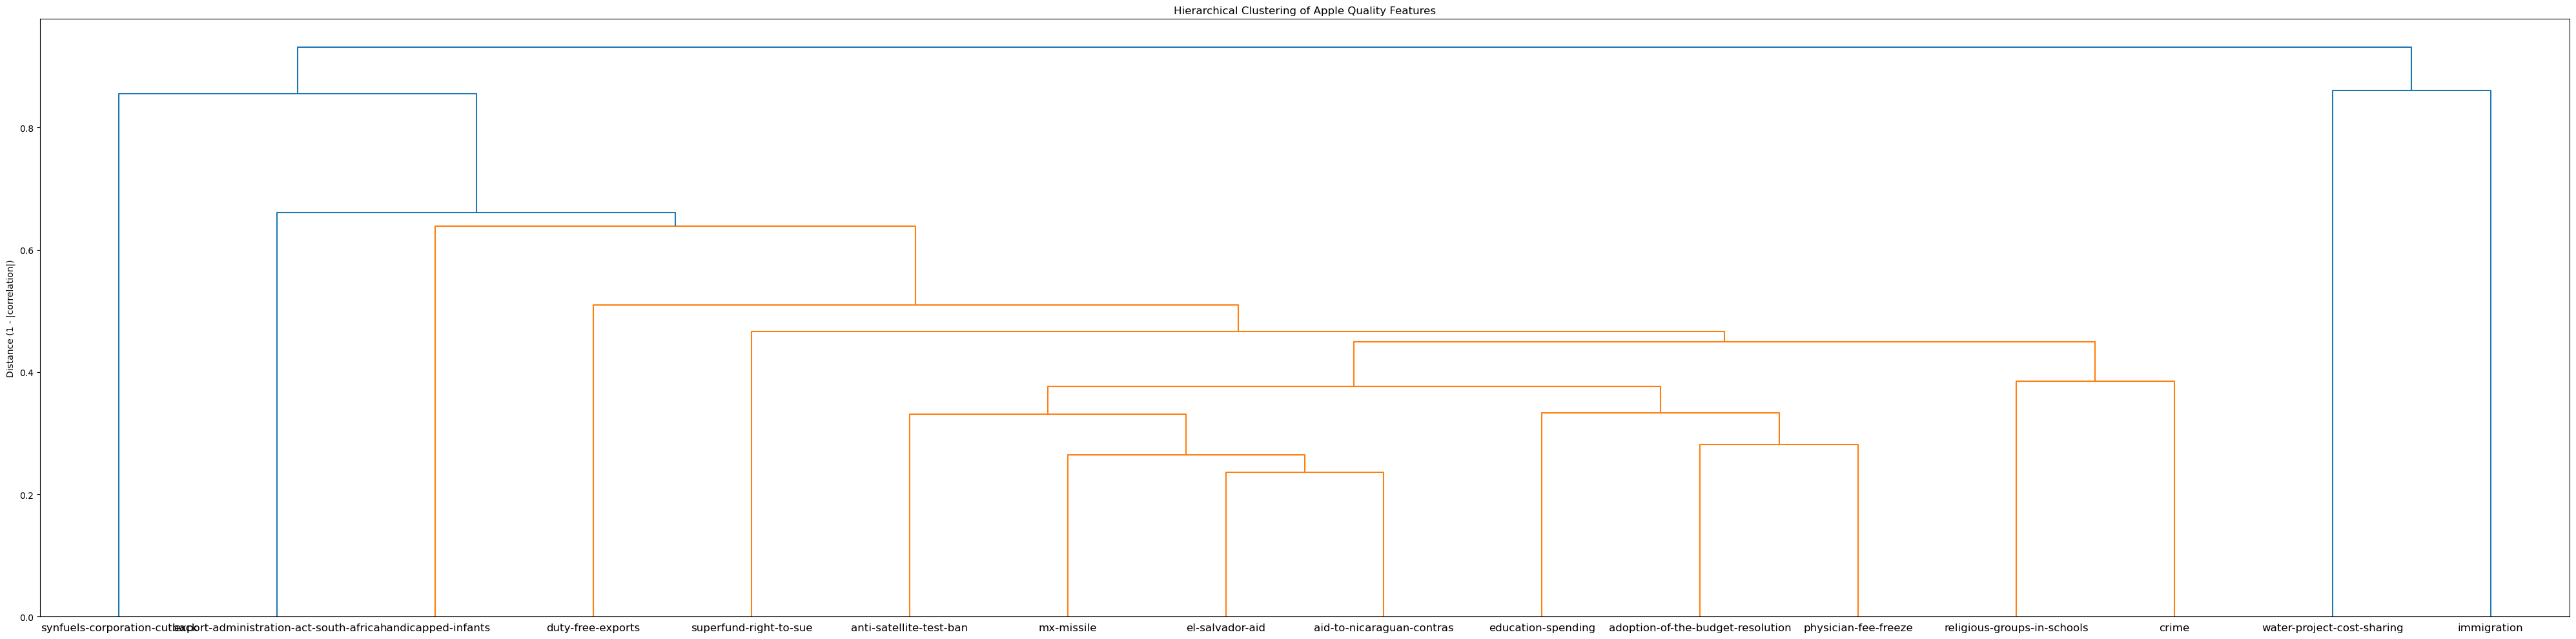

In [13]:
plt.figure(figsize=(40, 10))
dendrogram = hierarchy.dendrogram(z, labels=corr_matrix.columns, orientation='top', leaf_rotation=0)
plt.title('Hierarchical Clustering of Apple Quality Features')
plt.ylabel('Distance (1 - |correlation|)')
plt.tight_layout()
plt.savefig('feature_dendrogram.png')

In [14]:
dendrogram

{'icoord': [[75.0, 75.0, 85.0, 85.0],
  [65.0, 65.0, 80.0, 80.0],
  [55.0, 55.0, 72.5, 72.5],
  [105.0, 105.0, 115.0, 115.0],
  [95.0, 95.0, 110.0, 110.0],
  [63.75, 63.75, 102.5, 102.5],
  [125.0, 125.0, 135.0, 135.0],
  [83.125, 83.125, 130.0, 130.0],
  [45.0, 45.0, 106.5625, 106.5625],
  [35.0, 35.0, 75.78125, 75.78125],
  [25.0, 25.0, 55.390625, 55.390625],
  [15.0, 15.0, 40.1953125, 40.1953125],
  [5.0, 5.0, 27.59765625, 27.59765625],
  [145.0, 145.0, 155.0, 155.0],
  [16.298828125, 16.298828125, 150.0, 150.0]],
 'dcoord': [[0.0,
   np.float64(0.23594085060934422),
   np.float64(0.23594085060934422),
   0.0],
  [0.0,
   np.float64(0.26430377154433626),
   np.float64(0.26430377154433626),
   np.float64(0.23594085060934422)],
  [0.0,
   np.float64(0.33151151219827196),
   np.float64(0.33151151219827196),
   np.float64(0.26430377154433626)],
  [0.0, np.float64(0.28104596239831625), np.float64(0.28104596239831625), 0.0],
  [0.0,
   np.float64(0.333618002847604),
   np.float64(0.333618

In [15]:
feature_to_idx = {name: i for i, name in enumerate(feature_names)}

group_names = [
    [
        'adoption-of-the-budget-resolution',
        'physician-fee-freeze',
        'education-spending',
        'superfund-right-to-sue',
        'handicapped-infants',
        'duty-free-exports',
        'export-administration-act-south-africa'
    ],
    [
        'aid-to-nicaraguan-contras',
        'el-salvador-aid',
        'mx-missile',
        'anti-satellite-test-ban'
    ],
    [
        'crime',
        'immigration',
        'water-project-cost-sharing',
        'synfuels-corporation-cutback',
        'religious-groups-in-schools'
    ]
]

groups = [[feature_to_idx[name] for name in group] for group in group_names]

print("Feature groups (by index):", groups)

Feature groups (by index): [[2, 3, 11, 12, 0, 14, 15], [7, 4, 8, 6], [13, 9, 1, 10, 5]]


In [16]:
class DataWrapper:
    def __init__(self, indices, names=None):
        self.indices = indices
        self.data_names = names if names is not None else [f"f{i}" for i in range(len(indices))]

    def __len__(self):
        return len(self.indices)

    def __iter__(self):
        return iter(self.indices)

class Utility:
    def __init__(self, X_train, y_train, X_test, y_test, model_name, scorer, feature_names=None, random_state=42):
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.model_name = model_name
        self.scorer = scorer
        self.data = DataWrapper(list(range(X_train.shape[1])), feature_names)
        self.random_state = random_state
        self._cache = {}

    def __call__(self, subset):
        key = tuple(sorted(subset))
        if key in self._cache:
            return self._cache[key]
        if len(key) == 0:
            majority = np.bincount(self.y_train.astype(int)).argmax()
            y_pred = np.full_like(self.y_test, majority)
            score = self.scorer(self.y_test, y_pred)
            self._cache[key] = score
            return score
        model = get_model(self.model_name, self.random_state)
        model.fit(self.X_train[:, key], self.y_train)
        y_pred = model.predict(self.X_test[:, key])
        score = self.scorer(self.y_test, y_pred)
        self._cache[key] = score
        return score

In [17]:
from sklearn.metrics import accuracy_score, f1_score, mean_squared_error, r2_score, mean_absolute_error

def get_scorer(name):
    if name == "accuracy":
        return lambda y_true, y_pred: accuracy_score(y_true, y_pred)
    elif name == "f1_macro":
        return lambda y_true, y_pred: f1_score(y_true, y_pred, average="macro")
    elif name == "r2":
        return lambda y_true, y_pred: r2_score(y_true, y_pred)
    elif name == "mse":
        return lambda y_true, y_pred: -mean_squared_error(y_true, y_pred)  # Negative for maximization
    elif name == "rmse":
        return lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred))
    elif name == "mae":
        return lambda y_true, y_pred: -mean_absolute_error(y_true, y_pred)
    else:
        raise ValueError(f"Unknown scorer: {name}")

In [54]:
N_MC_ITERATIONS = 200000
RANDOM_STATE = 42
MODEL_NAME = "random_forest"
DATASET_NAME = "congress"
SCORING = "f1_macro"
METHODS = [ 'owen_exact']
OUTPUT_DIR = Path(f"./output/feature_valuation/{DATASET_NAME}_{MODEL_NAME}_{SCORING}_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [55]:
scorer = get_scorer(SCORING)
utility = Utility(X_train, y_train, X_test, y_test, MODEL_NAME, scorer, feature_names, RANDOM_STATE)

In [56]:
results = {}

if "owen_mc" in METHODS:
    val = montecarlo_owen_value(utility, groups, n_iterations=N_MC_ITERATIONS)
    results["owen_mc"] = val.values

if "owen_exact" in METHODS:
    val = exact_owen_value(utility, groups)
    results["owen_exact"] = val.values

results_df = pd.DataFrame([
    {"method": m, "feature": feature_names[i], "value": v}
    for m, vals in results.items() for i, v in enumerate(vals)
])

print(results_df)

        method                                 feature     value
0   owen_exact                     handicapped-infants  0.045801
1   owen_exact              water-project-cost-sharing  0.041334
2   owen_exact       adoption-of-the-budget-resolution  0.022653
3   owen_exact                    physician-fee-freeze -0.000993
4   owen_exact                         el-salvador-aid  0.000000
5   owen_exact             religious-groups-in-schools  0.034806
6   owen_exact                 anti-satellite-test-ban  0.076814
7   owen_exact               aid-to-nicaraguan-contras  0.024767
8   owen_exact                              mx-missile  0.053796
9   owen_exact                             immigration -0.000368
10  owen_exact            synfuels-corporation-cutback  0.062879
11  owen_exact                      education-spending  0.055543
12  owen_exact                  superfund-right-to-sue  0.093806
13  owen_exact                                   crime  0.019127
14  owen_exact           

In [52]:
model_accurcy = utility(range(X_train.shape[1]))
print(f"Model accuracy with all features: {model_accurcy:.4f}")

Model accuracy with all features: 0.9632


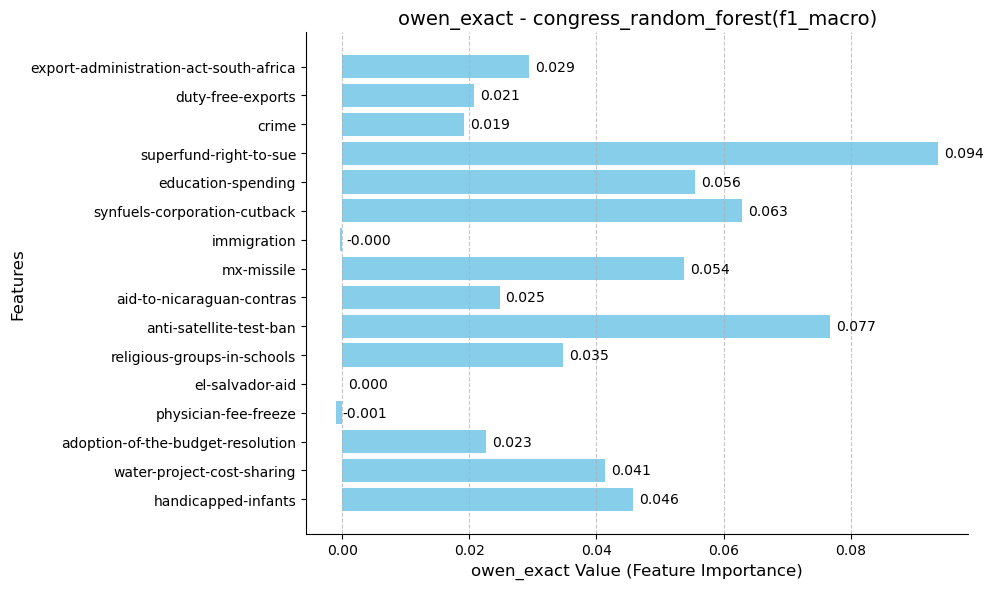

In [57]:
for method, vals in results.items():
    plot_single_valuation(
        vals, feature_names,
        method_name=method,
        title=f"{method} - {DATASET_NAME}_{MODEL_NAME}({SCORING})",
        output_path=OUTPUT_DIR / f"{DATASET_NAME}_{MODEL_NAME}_{method}_{SCORING}.png"
    )